# Conditional diffusion models

### Simple examples of conditional diffusion models

Once the framework for unconditional diffusion model is there, the general idea of conditional diffusion model is surprisingly simple

In this notebook, built on the previous notebook diffusion_intro.ipynb, we examine how to build a simple conditional diffusion model.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

from funs.SineWave_Dataset import SineWave_Square_DataSet
from funs.plotting import plot_batched_lines
from funs.scheduler import (
    add_noise_from_zero,
    add_noise_onestep_cum_sampler,
    ddpm_sampler,
    noise_scheduler,
)
from funs.time_embedding import get_sinusoidal_table
from funs.unet_1d import UNet1D

torch.manual_seed(7)
plt.rcParams["figure.figsize"] = (5, 3)

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print(f"Using device: {device}")

Using device: cuda


## A slightly more complicated dataset

Instead of SineWave_DataSet previously, we work with SineWave_DataSet in this notebook. For each sample, it outputs the frequency and a curve that is a sine wave if int(frequency) is an odd number, otherwise, a square wave with the same freqeuncy.

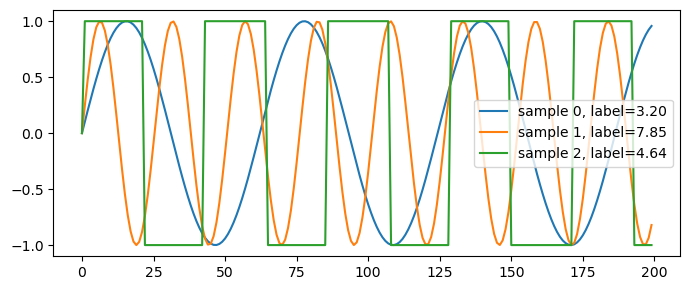

condition batch: (64, 1)
signal batch:    (64, 200)
Adopting a linear scheduler


In [24]:
dataset = SineWave_Square_DataSet(freq_max=10, n_dim=200)
data_loader = DataLoader(dataset, batch_size=64, shuffle=True)

conditions, clean_batch = next(iter(data_loader))
plot_batched_lines(
    clean_batch[:],
    conditions[:10],
    max_lines=3,
    figsize=(7, 3),
)

print("condition batch:", tuple(conditions.shape))
print("signal batch:   ", tuple(clean_batch.shape))

T = 500
schedule = noise_scheduler(T=T)

## Conditional diffusion model

In unconditional diffusion model, during training, for each sample, we are given :
- The sample $x_0$
- The generated noise 
- The noisy sample $x_t$, which is from the two above
Our goal is to estimate the noise given $x_t$ and the time step $t$

In conditional diffusion model, we are given the sample and their corresponding condition $c$. What's to do next? 
- Generate $x_t$: this step is identical to how it is done in unconditional diffusion model. No condition ($c$) involved
- The training goal is to estimate the generated noise as well. In conditional diffusion model, we estimate the generated noise given $x_t$, time step $t$ and the condition $c$


During sample generation, for conditional diffusion model, we follow the same procedure using the noise predictor that is based on $x_t$, $t$, and the conditioning. 


The differences are between unconditional diffusion model and **direct** conditional model



## Direct conditioning is one of several ways to condition a diffusion model

Two alternatives, not covered here:

- **Classifier-free guidance** builds directly on the direct conditional model above. Train the same
  $\epsilon_\theta(x_t,t,c)$, but swap $c$ for a null token $\varnothing$ on a
  fraction of training steps so one network learns both the conditional and the
  unconditional score; at sampling, extrapolate between them. Guidance weight
  $w=1$ recovers exactly the model above.

- **Classifier guidance** builds on the *unconditional* model instead. Keep
  $\epsilon_\theta(x_t,t)$ frozen, train a separate classifier $p_\phi(c\mid x_t)$
  on noisy inputs, and add $s\,\nabla_{x_t}\log p_\phi(c\mid x_t)$ to the score at
  sampling time. No conditional denoiser is trained.


We refer to direct conditioning diffusion model as conditioning diffusion model for simplicity in the rest of the notebook.


## How to inject the condition into the denoiser $\epsilon_\theta(x_t, t, c)$

The mechanism follows from the *shape* of $c$; it isn't a free choice.

**Start from $t$.** The timestep is itself a condition, and every diffusion network
already has a pathway for it: sinusoidal embedding → MLP → injected into every
residual block. A global $c$ can reuse that pathway unchanged.

### Global condition — class label, low-dimensional parameter vector, pooled text embedding

Embed $c$, then either

- **add** it to the timestep embedding, $e = \mathrm{MLP}(e_t)+\mathrm{MLP}(e_c)$, and
  inject as usual — simplest, no new machinery; or
- **modulate** (FiLM / AdaGN / adaLN): predict per-channel scale and shift from $e$,
  $$h \leftarrow \gamma(e)\odot\mathrm{Norm}(h)+\beta(e)$$
  Strictly more expressive — addition is the special case $\gamma\equiv 1$ — and the
  standard choice (ADM, DiT).

Either way the embedding enters *hidden features*, never $x_t$ itself.

### Spatially aligned condition — segmentation or depth map, low-res image, another field on the same grid

**Concatenate along channels at the input**, $[\,x_t\,;\,c\,]$, widening the first
convolution. This works precisely *because* position $i$ of $c$ corresponds to
position $i$ of $x_t$, so the convolution can exploit the alignment. Resample if
resolutions differ. Broadcasting a global vector across all positions and
concatenating also works, but wastes capacity.

### Variable-length or set-structured condition — text tokens, a sequence of observations

**Cross-attention**: queries from image features, keys and values from $c$'s tokens.
Handles arbitrary $|c|$ and lets different spatial locations attend to different
parts of the condition. Cost $O(HW\cdot L_c)$.

### Cross-cutting

- **Zero-initialize** the new conditioning path (zero convs, adaLN-Zero) so training
  starts at exactly the unconditioned model and the condition's influence grows from
  zero. Important whenever a pretrained model is involved.
- **Reserve a null token $\varnothing$** — a learned "no condition" embedding, or an
  all-zero channel for the concatenation case — if classifier-free guidance may be
  used later.
- **These compose.** Text-to-image models typically use all three at once: $t$ and
  pooled text by modulation, text tokens by cross-attention, spatial control by
  concatenation.

## Our specific model
### How the embedding information enters the neural network
Our neural network used in the previous notebook can work with both conditional and unconditional diffusion model. 
At Line 121 in unet_1d.py, the conditioning enters the neural network via the line

````python
emb = self.cond_embed(t, cond)
````
Here t is the time step for sinusoidal embedding introduced in the previous notebook. How cond_emb works will be examined later. 

The emb here contains the embedded information of the time step and cond (the conditioning). 
It is used as input in various places throughout the forward model. They are all cases of the class ResBlock1D_conditional. Within it (lines 54 and 61):
````python
self.emb_proj = nn.Linear(emb_dim, out_ch)
h = h + self.emb_proj(emb).unsqueeze(-1)
````
The emb is first projected to the dim of the output channel, and then added to h. 

### How the time step and conditioning are put to gether (i.e., what does cond_embed do)
We can examine ConditionEmbedding, which is the class of the case cond_embed (lines 33-41 in unet_1d.py):
````python
if cond is not None:
    if cond.ndim == 1:
        cond = cond.unsqueeze(-1)
    c_emb = self.cond_proj(cond.float())
    
    return t_emb + c_emb

else:
    return t_emb
````
Namely, if cond is None, we simply ignore it, and the conditioning is solely time step
Lines 36-41:
````python
c_emb = self.cond_proj(cond.float())
return t_emb + c_emb
````
where
````python
self.cond_proj = nn.Sequential(
    nn.Linear(cond_dim, out_dim),
    nn.SiLU(),
    nn.Linear(out_dim, out_dim),
)
````
This is similarly to how time is embedded. In summary, time and condition are projected to the same dim, and then add together to get the emb in line 121 of unet_1d.py


Now let's try it. The cell below has an additional argument, which is dummy_c


In [4]:
model = UNet1D(
    in_channels=1,
    base_channels=64,
    t_steps=500,
    t_dim=64,
    cond_dim=1,
    emb_dim=72,
)

dummy_x_t = torch.randn(12, 1, 200)
dummy_t = torch.randint(0, T, (12,))
dummy_c = torch.randn(12, 1)

model.eval()
with torch.no_grad():
    dummy_prediction = model(dummy_x_t, dummy_t, dummy_c)

assert dummy_prediction.shape == dummy_x_t.shape
print("model input: ", tuple(dummy_x_t.shape))
print("model output:", tuple(dummy_prediction.shape))

model input:  (12, 1, 200)
model output: (12, 1, 200)


## Training
We only need to make a few changes in the cell below compared to the one in the unconditional diffusion model intro (diffusion_intro.ipynb):


From:
````python
for batch_index, (_, x_clean_batch) in enumerate(data_loader):
````
to:
````python
for batch_index, (x_label, x_clean_batch) in enumerate(data_loader):
````


Add:
````python
x_label_batch = x_label_batch.to(device)
````
So that the conditioning is moved to the same device.

From:
````python
predicted_noise = model(x_t_batch, t_batch, None)
````
To:
````python
predicted_noise = model(x_t_batch, t_batch, x_label_batch)
````

In [ ]:
TRAIN_MODEL = True
EPOCHS = 100
weights_path = Path("trained_parameters/conditional.pt")

model = model.to(device)
schedule_device = {name: values.to(device) for name, values in schedule.items()}

if TRAIN_MODEL:
    loss_fn = nn.MSELoss()
    optimizer = optim.AdamW(model.parameters(), lr=5e-4)
    model.train()

    for epoch_index in range(EPOCHS):
        running_loss = 0.0

        for batch_index, (x_label_batch, x_clean_batch) in enumerate(data_loader):
            x_clean_batch = x_clean_batch.to(device)
            x_label_batch = x_label_batch.to(device)
            t_batch = torch.randint(
                0,
                T,
                (x_clean_batch.shape[0],),
                device=device,
            )

            x_t_batch, target_noise = add_noise_from_zero(
                x_clean_batch,
                t_batch,
                schedule_device,
                device,
            )
            x_t_batch = x_t_batch.unsqueeze(1)
            target_noise = target_noise.unsqueeze(1)

            optimizer.zero_grad()
            predicted_noise = model(x_t_batch, t_batch, x_label_batch)
            loss = loss_fn(predicted_noise, target_noise)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        mean_loss = running_loss / len(data_loader)
        print(f"epoch {epoch_index + 1:02d}: mean loss={mean_loss:.6f}")
else:
    state_dict = torch.load(weights_path, map_location=device, weights_only=True)
    model.load_state_dict(state_dict)
    print(f"Loaded pretrained weights from {weights_path}.")

model.eval()

epoch 01: mean loss=0.019948
epoch 02: mean loss=0.019213
epoch 03: mean loss=0.019683
epoch 04: mean loss=0.019238
epoch 05: mean loss=0.018987
epoch 06: mean loss=0.018635
epoch 07: mean loss=0.018343
epoch 08: mean loss=0.019019
epoch 09: mean loss=0.019146
epoch 10: mean loss=0.018128
epoch 11: mean loss=0.019466
epoch 12: mean loss=0.018406
epoch 13: mean loss=0.019065
epoch 14: mean loss=0.018714
epoch 15: mean loss=0.018372
epoch 16: mean loss=0.018688
epoch 17: mean loss=0.018107
epoch 18: mean loss=0.019093
epoch 19: mean loss=0.018461
epoch 20: mean loss=0.017885
epoch 21: mean loss=0.018022
epoch 22: mean loss=0.018363
epoch 23: mean loss=0.017949
epoch 24: mean loss=0.018012
epoch 25: mean loss=0.018112


## Generation
Now we can check how the samples are generated.
Similarly, the only change that is made here is 
adding the cond
````python
    cond = torch.tensor([1,2,3]).to(device),
````

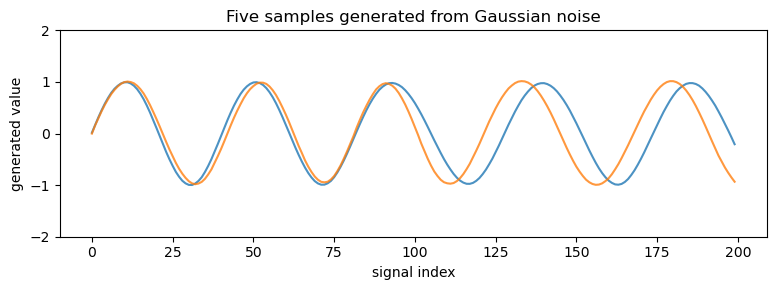

In [32]:
torch.manual_seed(11)

generated = ddpm_sampler(
    sample_dim=200,
    n_sample=2,
    noise_dict=schedule_device,
    cond = torch.tensor([5.3, 4.2]).to(device),
    model=model,
    device=device,
)

plt.figure(figsize=(8, 3))
for sample in generated:
    plt.plot(sample[0].detach().cpu(), alpha=0.8)

plt.xlabel("signal index")
plt.ylabel("generated value")
plt.title("Five samples generated from Gaussian noise")
plt.ylim(-2, 2)
plt.tight_layout()
plt.show()

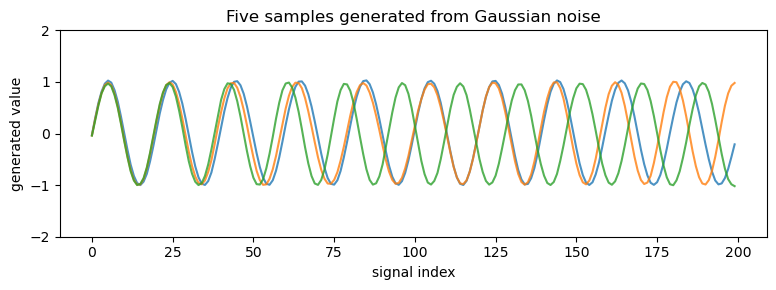

In [20]:
torch.manual_seed(11)

generated = ddpm_sampler(
    sample_dim=200,
    n_sample=3,
    noise_dict=schedule_device,
    cond = torch.tensor([11,12,12]).to(device),
    model=model,
    device=device,
)

plt.figure(figsize=(8, 3))
for sample in generated:
    plt.plot(sample[0].detach().cpu(), alpha=0.8)

plt.xlabel("signal index")
plt.ylabel("generated value")
plt.title("Five samples generated from Gaussian noise")
plt.ylim(-2, 2)
plt.tight_layout()